Start from saved fits and examine explicit changes to model parameters. Each sweep holds
 the remaining values fixed, simulates the same study lists, and saves responses and comparisons.
 This is a mechanism check; it performs no refitting.

## Parameters and setup
 `fit_paths` names the baselines. Each `parameter_sweeps` entry names its fit, parameter and values.
 Supply one entry for an independent work unit. The example includes encoding-drift sweeps and a
 separate switch of temporal emotional modulation. For another model, replace these entries with
 parameters that model uses. Boolean switches retain their boolean type.

 Paths are relative to the working folder. Model construction comes from the saved fit. Use
 distinct output folders for independent jobs; the sweep name separates products within a job.

In [1]:
#| code-summary: "1 — Configure baselines and parameter interventions"


# Observations and work-unit selection
data_path = "data/Dupertuys2026.h5"

# Saved model fits
fit_paths = {
    "CMR": "data/fits/Dupertuys2026_CMR_demo.json",
    "eCMR_source_only": "data/fits/Dupertuys2026_eCMR_source_only.json",
    "eCMR_broad": "data/fits/Dupertuys2026_eCMR_broad.json",
}
model_labels = {
    "CMR": "CMR",
    "eCMR_source_only": "Source-only eCMR",
    "eCMR_broad": "Broader eCMR",
}

# Controlled interventions
parameter_sweeps = {
    "CMR_encoding": {
        "fit": "CMR",
        "parameter": "encoding_drift_rate",
        "values": [0.2, 0.5, 0.8],
    },
    "eCMR_source_only_encoding": {
        "fit": "eCMR_source_only",
        "parameter": "encoding_drift_rate",
        "values": [0.2, 0.5, 0.8],
    },
    "eCMR_broad_encoding": {
        "fit": "eCMR_broad",
        "parameter": "encoding_drift_rate",
        "values": [0.2, 0.5, 0.8],
    },
    "temporal_emotional_modulation": {
        "fit": "eCMR_broad",
        "parameter": "phi_emot_modulates_temporal",
        "values": [False, True],
    },
}
trial_query = None
max_subjects = 0
subject_indices = []

# Output locations and regeneration
output_dir = "results/parameter_shifting"

# Simulation settings
experiment_count = 10
simulation_seed = 2


# Behavioral comparisons and figure settings
comparison_analysis_configs = [
    {"target": "jaxcmr.analyses.spc.plot_spc", "title": "Recall by study position"},
    {
        "target": "jaxcmr.analyses.pnr.plot_pnr",
        "title": "First recall",
        "kwargs": {"query_recall_position": 0},
    },
    {
        "target": "jaxcmr.analyses.crp.plot_crp",
        "title": "Temporal transitions",
        "kwargs": {"max_lag": 5},
    },
    {
        "target": "jaxcmr.analyses.cat_recall_rate.plot_cat_recall_rate",
        "title": "Category recall within mixed lists",
        "contrast_name": "Item category",
        "trial_query": "data['list_type'] == 1",
        "kwargs": {
            "category_field": "valence",
            "category_values": [-1, 0],
            "category_labels": ["Emotional", "Neutral"],
            "valid_field": "pres_itemnos",
        },
    },
]
single_analysis_configs = []
analysis_trial_query = "jnp.all(data['pres_itemnos'] > 0, 1)"
confidence_level = 0.95
plot_seed = 0
filter_repeated_recalls = False
figure_dir = None
figure_size = (10, 4.8)
figure_str = "model_and_data"  # Empty displays figures without saving.


# Numerical precision
enable_x64 = True
redo_figures = True


In [2]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "d919f1ad6aeacc7a36c40b96e365316219a7f40a"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs([data_path, *fit_paths.values()], revision=revision)


In [3]:
#| code-summary: "3 — Import packages"

import hashlib
import json
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

import jaxcmr
from jaxcmr import repetition
from jaxcmr.helpers import (
    generate_trial_mask,
    import_from_string,
    load_data,
    save_dict_to_hdf5,
    save_figure,
)
from jaxcmr.simulation import parameter_shifted_simulate_h5_from_h5, simulate_h5_from_h5


In [4]:
#| code-summary: "4 — Define feature loading and model construction"


def load_features(spec):
    semantic = np.load(spec["embedding_path"]) if spec.get("embedding_path") else None
    categorical = (
        np.load(spec["emotion_feature_path"])[
            :,
            int(spec.get("feature_column", 6)) : int(spec.get("feature_column", 6)) + 1,
        ]
        if spec.get("emotion_feature_path")
        else None
    )
    if spec.get("concat_features", False):
        return np.concatenate([categorical, semantic], axis=1)
    return categorical if categorical is not None else semantic


def construct_model(spec):
    return import_from_string(spec["model_factory"])(
        **{name: import_from_string(path) for name, path in spec["components"].items()}
    )


In [5]:
#| code-summary: "5 — Load observations and establish runtime settings"

jax.config.update("jax_enable_x64", enable_x64)
np.random.seed(plot_seed)
data_path = Path(data_path)
output_dir = Path(output_dir)
output_dir.mkdir(parents=True, exist_ok=True)
data = load_data(str(data_path))
data_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
subjects = np.asarray(data["subject"]).ravel()


## Load the baseline fits

In [6]:
#| code-summary: "6 — Load baseline fits and select their observations"

fit_paths = {name: Path(path) for name, path in fit_paths.items()}
records = {name: json.loads(path.read_text()) for name, path in fit_paths.items()}
if not records:
    raise ValueError("Supply at least one saved fit.")
display_labels = {
    name: model_labels.get(name, record.get("label", name))
    for name, record in records.items()
}
selections = {}
for name, record in records.items():
    if record.get("data_sha256", data_sha256) != data_sha256:
        raise ValueError(f"{name}: the fit refers to a different observation file.")
    if trial_query is None and "selected_trial_indices" in record:
        mask = (
            jnp.zeros(len(subjects), dtype=bool)
            .at[jnp.asarray(record["selected_trial_indices"], dtype=int)]
            .set(True)
        )
    else:
        mask = generate_trial_mask(
            data,
            trial_query
            if trial_query is not None
            else record.get("trial_query", record.get("data_query")),
        )
    subject_ids = np.unique(subjects)
    if max_subjects:
        subject_ids = subject_ids[:max_subjects]
    if subject_indices:
        subject_ids = subject_ids[np.asarray(subject_indices, dtype=int)]
    mask &= jnp.isin(data["subject"].ravel(), subject_ids)
    if not record.get("pooled", record["fits"]["subject"] == [-1]):
        mask &= jnp.isin(
            data["subject"].ravel(), jnp.asarray(record["fits"]["subject"])
        )
    if not bool(mask.any()):
        raise ValueError(f"{name}: no observations match the selected work unit.")
    selections[name] = mask
    print(display_labels[name], "—", int(mask.sum()), "lists; fit:", fit_paths[name])


CMR — 492 lists; fit: data/fits/Dupertuys2026_CMR_demo.json
Source-only eCMR — 492 lists; fit: data/fits/Dupertuys2026_eCMR_source_only.json
Broader eCMR — 492 lists; fit: data/fits/Dupertuys2026_eCMR_broad.json


## Simulate controlled changes
 Each sweep includes its fitted baseline. Use common random draws and the same observations and
 repetition count across values. Remaining fitted parameters stay unchanged. Responses preserve
 original participant IDs. The default forced-count simulator conditions on observed recall lengths.

 A switch such as `phi_emot_modulates_temporal` changes a mechanism at the baseline's parameter
 values. Comparing separately optimized models also allows the other estimates to change; those
 are different scientific comparisons. Each saved response file records its baseline and intervention.

In [7]:
#| code-summary: "7 — Prepare and describe the configured parameter sweeps"

sweep_inputs = {}
base_figure_dir = Path(figure_dir) if figure_dir is not None else output_dir
for sweep_name, sweep in parameter_sweeps.items():
    model_name = sweep["fit"]
    fit_record = records[model_name]
    parameter = sweep["parameter"]
    values = sweep["values"]
    if not values or len(set(values)) != len(values):
        raise ValueError(f"{sweep_name}: supply distinct parameter values.")
    selected_trials = selections[model_name]
    is_pooled = fit_record.get("pooled", fit_record["fits"]["subject"] == [-1])
    subject_parameters = {
        key: jnp.asarray(val) for key, val in fit_record["fits"].items()
    }
    if is_pooled:
        ids = jnp.unique(data["subject"].ravel()[selected_trials])
        subject_parameters = {
            key: jnp.repeat(val, len(ids))
            for key, val in subject_parameters.items()
            if key != "subject"
        }
        subject_parameters["subject"] = ids
    fixed = (
        fit_record.get("fit_configuration", {})
        .get("parameters", {})
        .get("fixed", fit_record["fixed"])
    )
    for key, value in fixed.items():
        if isinstance(value, bool):
            subject_parameters[key] = subject_parameters[key].astype(bool)
    if parameter not in subject_parameters:
        raise ValueError(
            f"{sweep_name}: {parameter} is absent from the baseline parameters."
        )
    print(
        sweep_name,
        "— baseline:",
        model_labels.get(model_name, model_name),
        "— varied parameter:",
        parameter,
    )
    if is_pooled:
        print(f"Shared baseline {parameter}:", subject_parameters[parameter][0].item())
    else:
        print(
            tabulate(
                zip(
                    np.asarray(subject_parameters["subject"]),
                    np.asarray(subject_parameters[parameter]),
                ),
                headers=["Subject", "Baseline value"],
            )
        )
    sweep_inputs[sweep_name] = {
        "fit_name": model_name,
        "parameter": parameter,
        "values": values,
        "parameters": subject_parameters,
        "trial_mask": selected_trials,
    }


CMR_encoding — baseline: CMR — varied parameter: encoding_drift_rate
Shared baseline encoding_drift_rate: 0.6812013948529274


eCMR_source_only_encoding — baseline: Source-only eCMR — varied parameter: encoding_drift_rate
Shared baseline encoding_drift_rate: 0.6785235060258634
eCMR_broad_encoding — baseline: Broader eCMR — varied parameter: encoding_drift_rate
Shared baseline encoding_drift_rate: 0.6581157240934907
temporal_emotional_modulation — baseline: Broader eCMR — varied parameter: phi_emot_modulates_temporal
Shared baseline phi_emot_modulates_temporal: True


In [8]:
#| code-summary: "8 — Simulate and save each baseline and intervention"

all_shifted_paths = {}
for sweep_name, prepared in sweep_inputs.items():
    model_name = prepared["fit_name"]
    fit_record = records[model_name]
    parameter = prepared["parameter"]
    values = prepared["values"]
    subject_parameters = prepared["parameters"]
    selected_trials = prepared["trial_mask"]
    model_factory = construct_model(fit_record)
    features = load_features(fit_record)
    paths = {}

    cases = [{"label": "Fitted baseline", "value": None}]
    for value in values:
        cases.append({"label": str(value), "value": value})
    for case in cases:
        label, value = case["label"], case["value"]
        if value is None:
            simulated = simulate_h5_from_h5(
                model_factory,
                data,
                features,
                subject_parameters,
                selected_trials,
                experiment_count=experiment_count,
                rng=jax.random.split(jax.random.PRNGKey(simulation_seed))[1],
                simulate_trial_fn=import_from_string(fit_record["simulation_function"]),
            )
        else:
            simulated = parameter_shifted_simulate_h5_from_h5(
                model_factory,
                data,
                features,
                subject_parameters,
                selected_trials,
                experiment_count=experiment_count,
                varied_parameter=parameter,
                parameter_values=[value],
                rng=jax.random.PRNGKey(simulation_seed),
                simulate_trial_fn=import_from_string(fit_record["simulation_function"]),
            )[0]
        path = (
            output_dir
            / sweep_name
            / ("baseline.h5" if value is None else f"{parameter}_{value}.h5")
        )
        path.parent.mkdir(parents=True, exist_ok=True)
        save_dict_to_hdf5(simulated, str(path))
        path.with_suffix(".json").write_text(
            json.dumps(
                {
                    "baseline_fit_sha256": hashlib.sha256(
                        fit_paths[model_name].read_bytes()
                    ).hexdigest(),
                    "baseline_fits": fit_record["fits"],
                    "data_sha256": data_sha256,
                    "selected_trial_indices": np.flatnonzero(
                        np.asarray(selected_trials)
                    ).tolist(),
                    "model_factory": fit_record["model_factory"],
                    "components": fit_record["components"],
                    "simulation_function": fit_record["simulation_function"],
                    "feature_sha256": hashlib.sha256(features.tobytes()).hexdigest()
                    if features is not None
                    else None,
                    "parameter": parameter,
                    "value": value,
                    "seed": simulation_seed,
                    "experiment_count": experiment_count,
                    "jaxcmr_version": jaxcmr.__version__,
                    "jax_version": jax.__version__,
                    "jax_enable_x64": enable_x64,
                },
                indent=2,
            )
            + "\n"
        )
        paths[label] = str(path)
    all_shifted_paths[sweep_name] = paths


In [9]:
#| code-summary: "9 — Prepare comparisons of saved sweep results"

comparison_groups = []
observed = dict(data)
if filter_repeated_recalls:
    observed["recalls"] = repetition.filter_repeated_recalls(observed["recalls"])
for sweep_name, paths in all_shifted_paths.items():
    sweep_figure_dir = base_figure_dir / sweep_name
    sweep_figure_dir.mkdir(parents=True, exist_ok=True)
    if not redo_figures:
        continue
    response_paths = [None, *paths.values()]  # None selects the observed responses.
    curve_labels = ["Observed", *paths.keys()]
    shared_settings = {
        "trial_mask": sweep_inputs[sweep_name]["trial_mask"],
        "figure_dir": sweep_figure_dir,
    }
    comparison_groups.append(
        {
            **shared_settings,
            "analyses": comparison_analysis_configs,
            "paths": response_paths,
            "labels": curve_labels,
            "suffix": "",
        }
    )
    for dataset_index, (path, label) in enumerate(zip(response_paths, curve_labels)):
        comparison_groups.append(
            {
                **shared_settings,
                "analyses": single_analysis_configs,
                "paths": [path],
                "labels": [label],
                "suffix": f"_single_{dataset_index}",
            }
        )


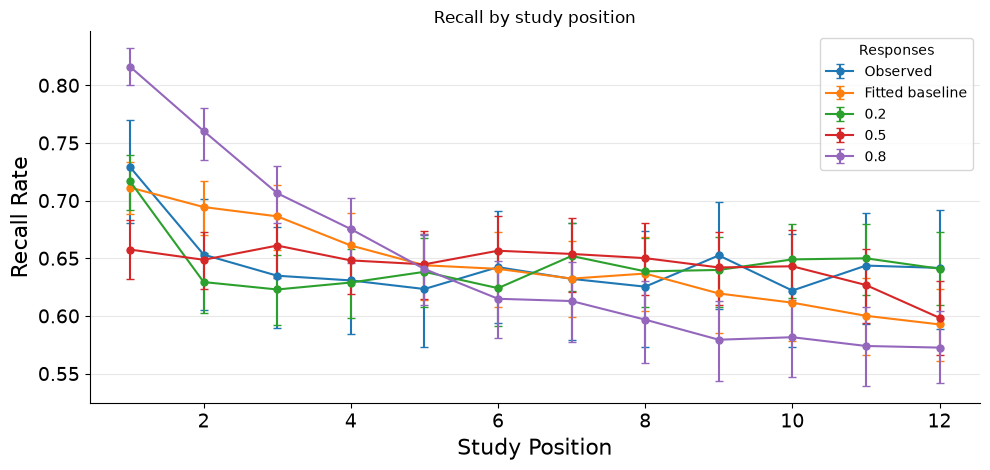

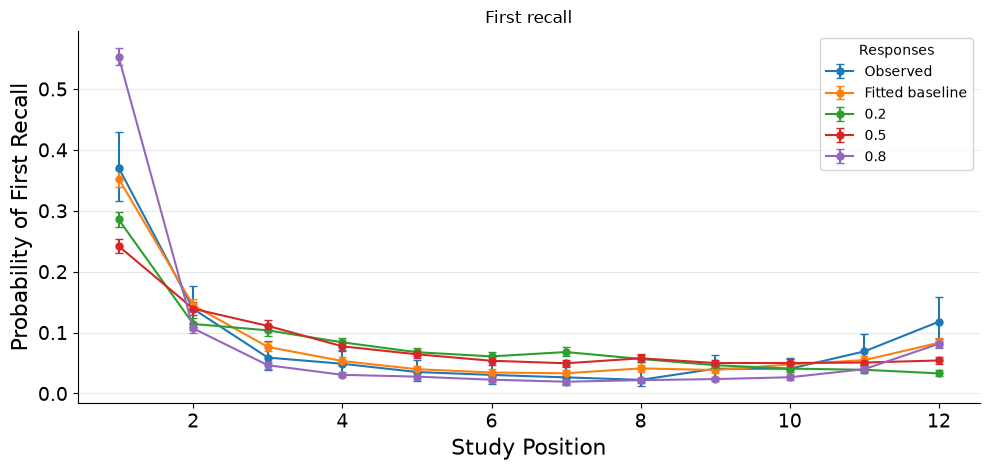

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


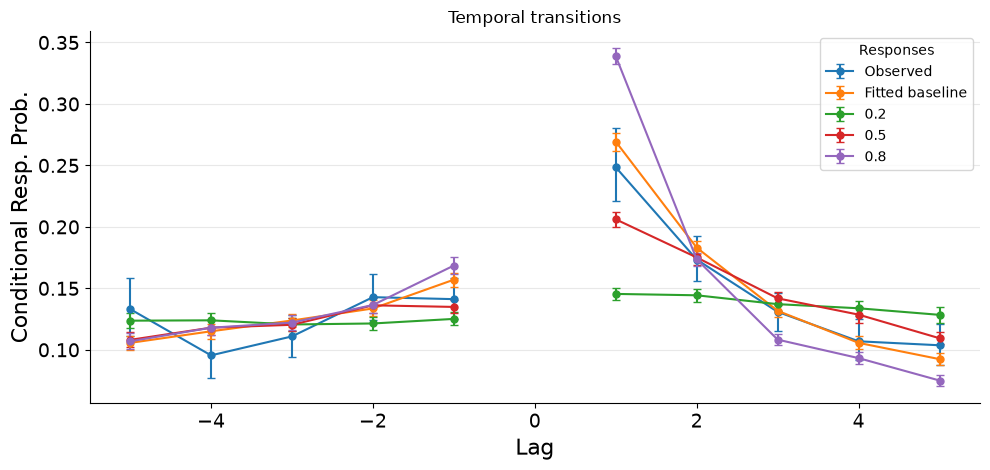

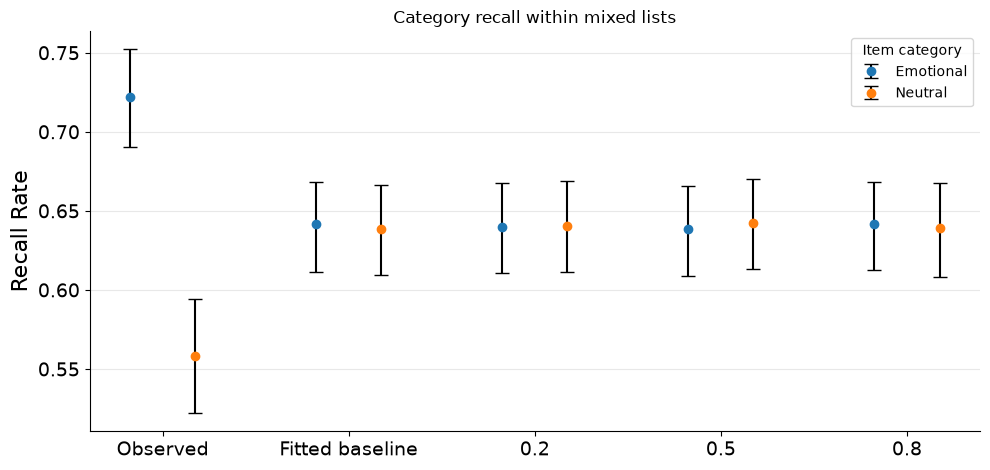

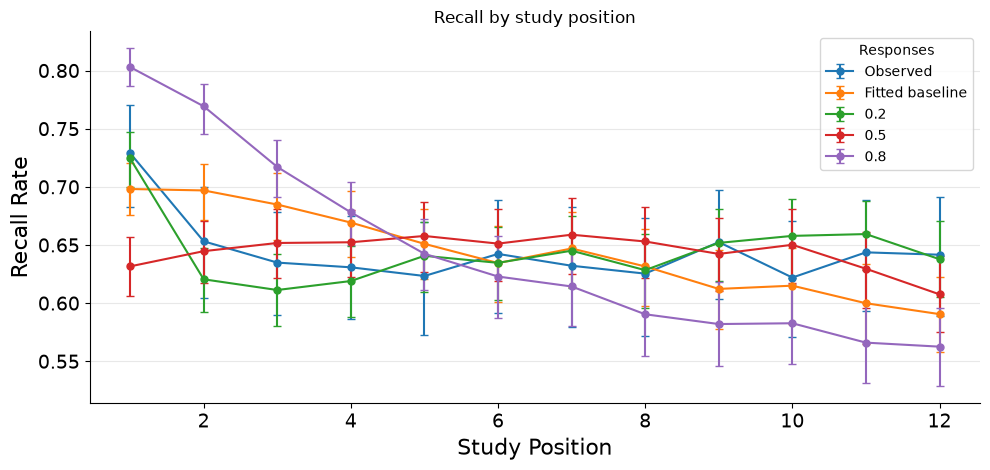

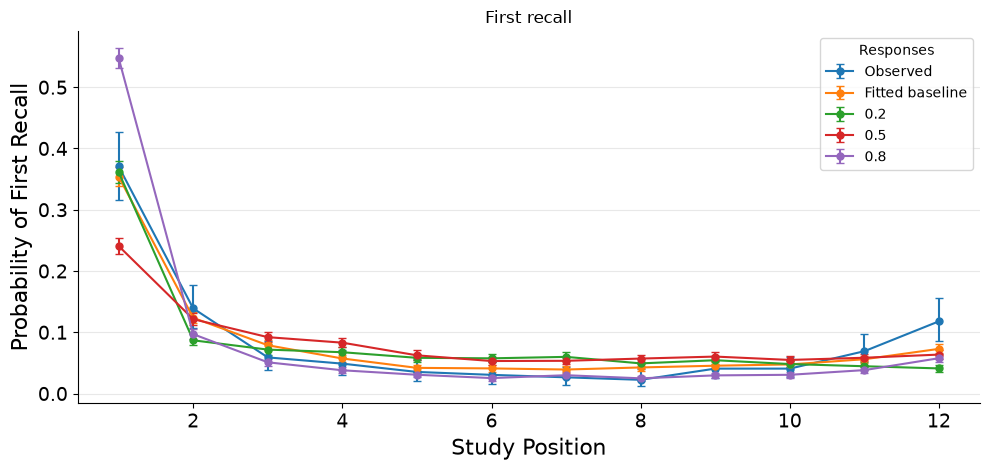

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


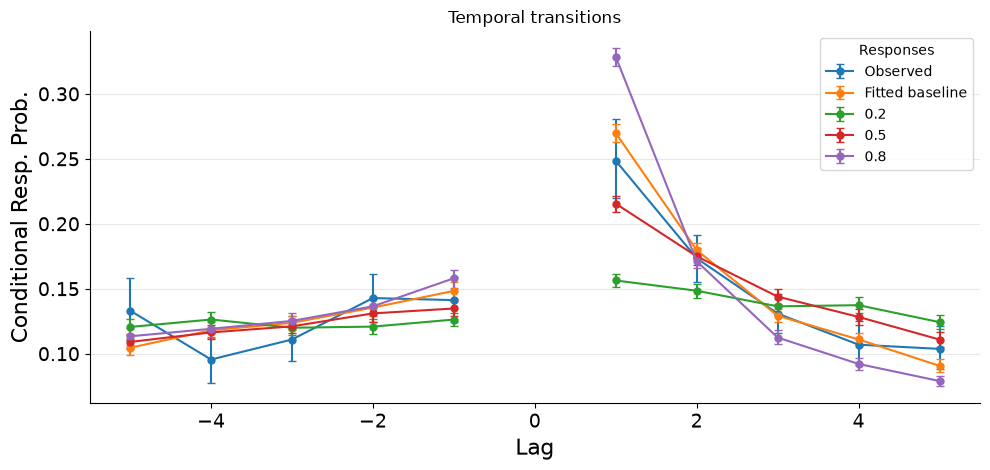

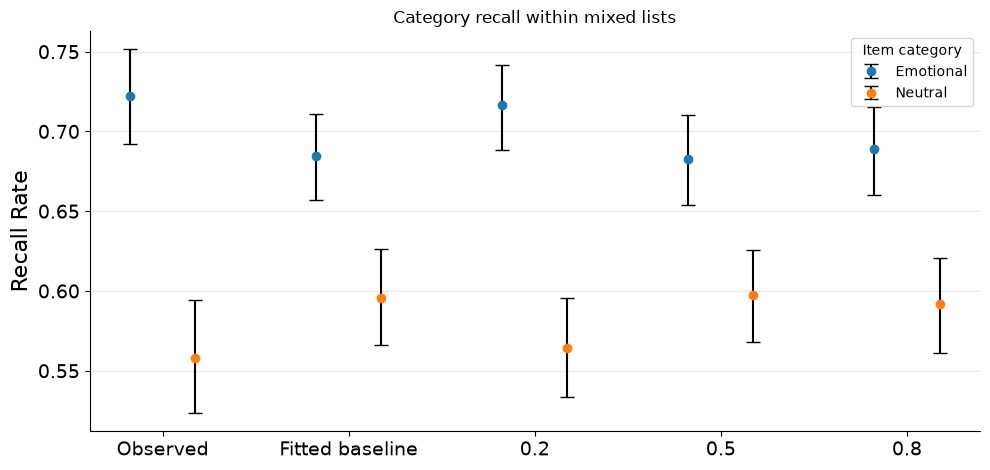

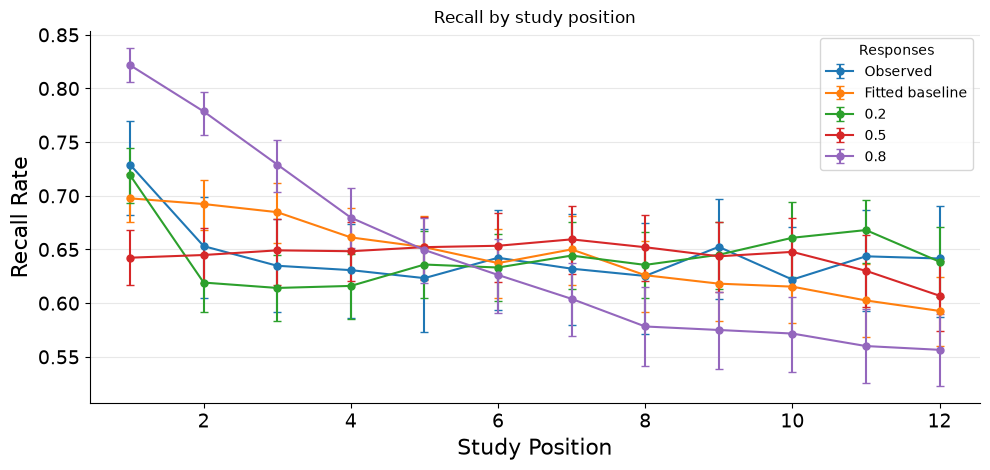

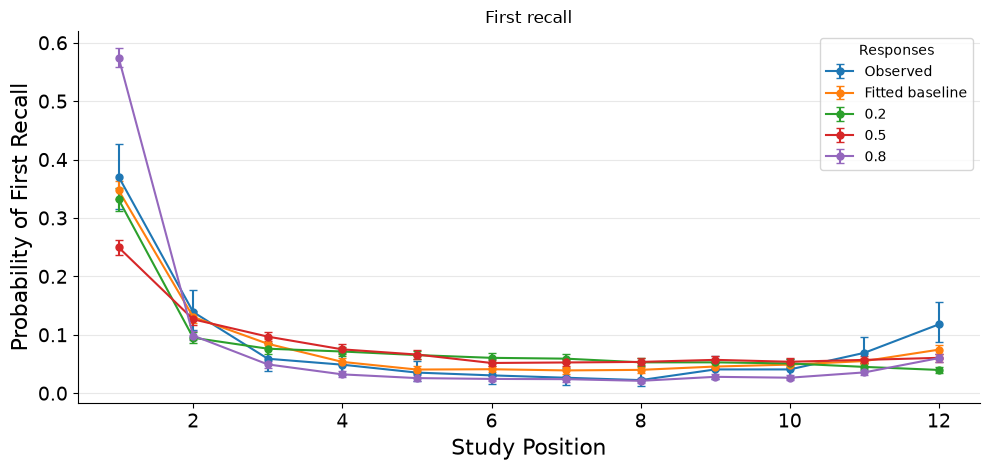

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


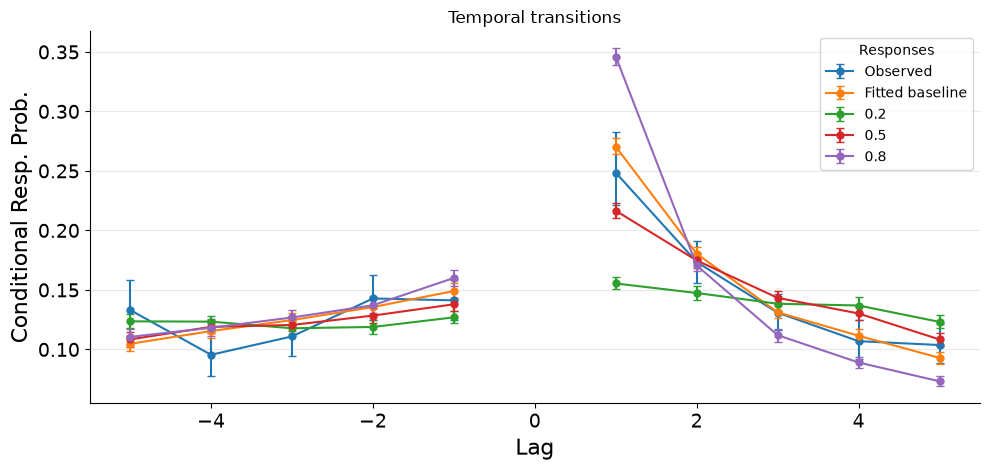

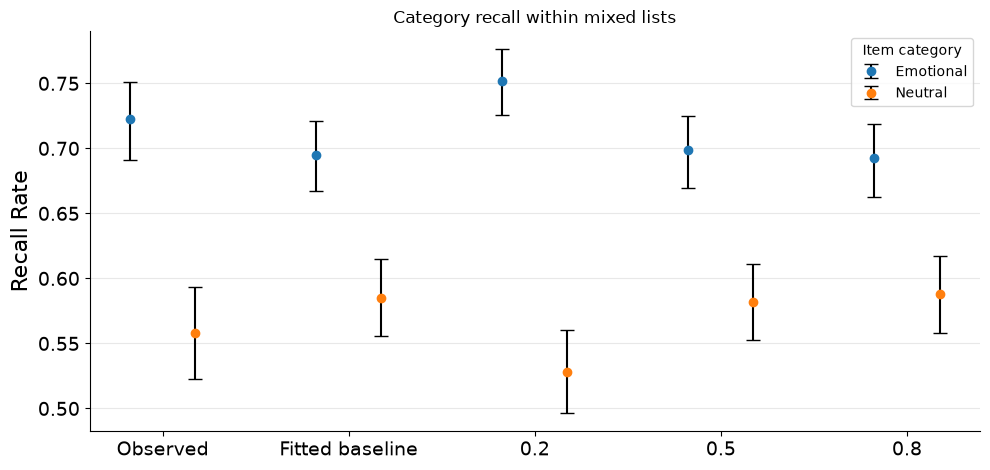

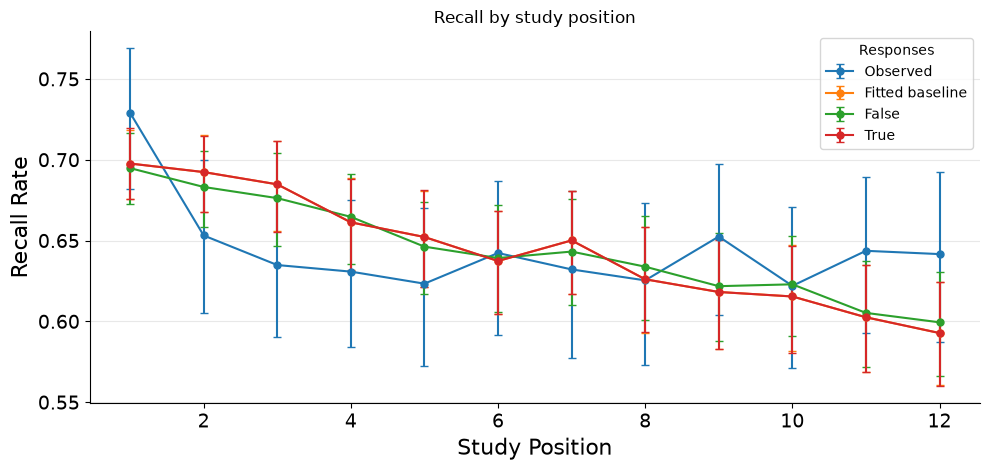

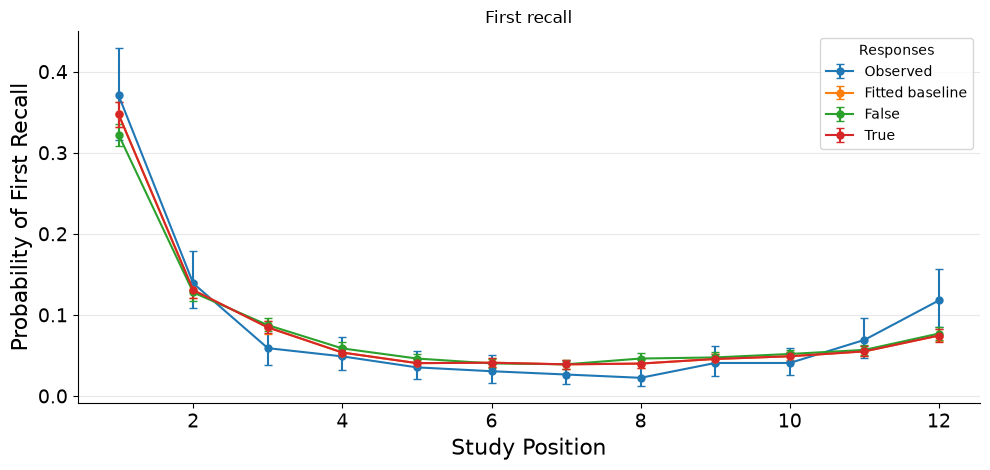

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


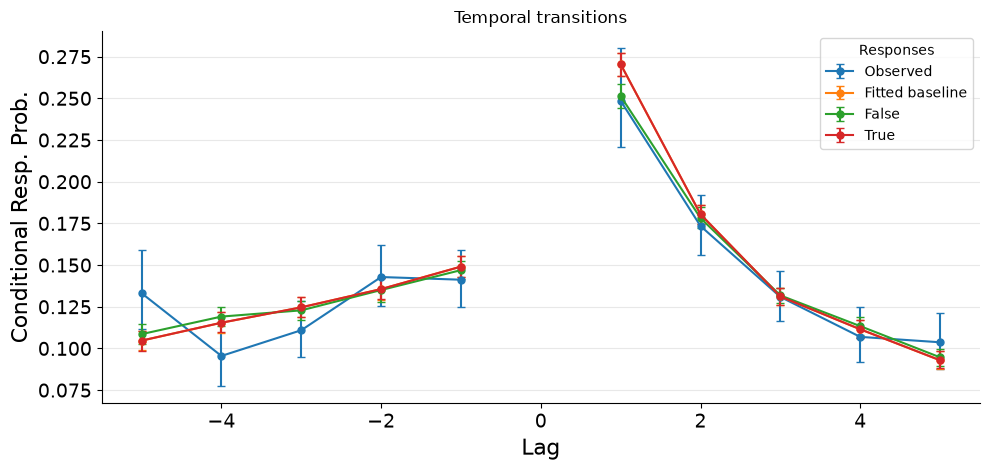

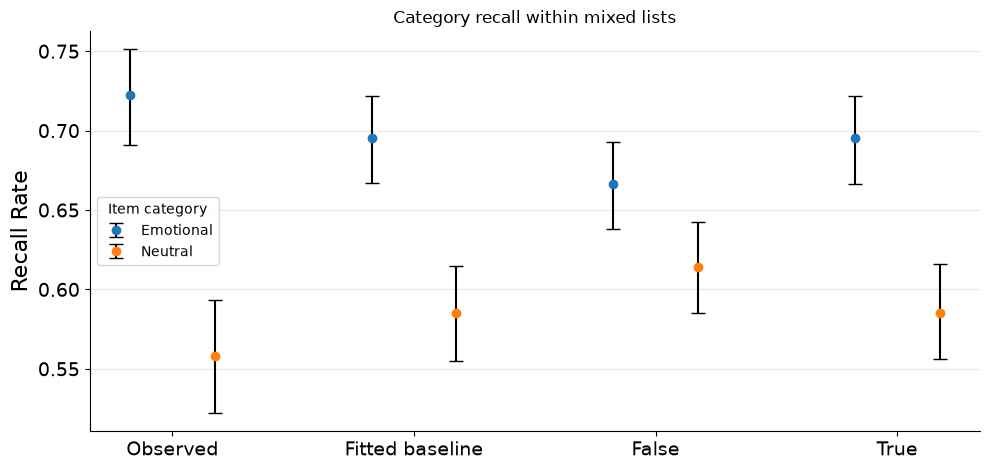

In [10]:
#| code-summary: "10 — Load one comparison at a time and plot its benchmarks"

for group in comparison_groups:
    analysis_configs = group["analyses"]
    if not analysis_configs:
        continue
    panel_data = []
    for path in group["paths"]:
        dataset = observed if path is None else load_data(path)
        if path is not None and filter_repeated_recalls:
            dataset["recalls"] = repetition.filter_repeated_recalls(dataset["recalls"])
        panel_data.append(dataset)
    curve_labels = group["labels"]
    figure_suffix = group["suffix"]
    figure_dir = group["figure_dir"]
    comparison_mask = group["trial_mask"]
    for analysis_index, analysis_config in enumerate(analysis_configs):
        plotter = import_from_string(analysis_config["target"])
        masks = [
            generate_trial_mask(
                dataset, analysis_config.get("trial_query", analysis_trial_query)
            )
            for dataset in panel_data
        ]
        masks = [
            trial_mask & comparison_mask if dataset is observed else trial_mask
            for dataset, trial_mask in zip(panel_data, masks)
        ]
        fig, ax = plt.subplots(figsize=analysis_config.get("figsize", figure_size))
        plot_options = {
            "labels": analysis_config.get("labels", curve_labels),
            "contrast_name": analysis_config.get("contrast_name", "Responses"),
            "confidence_level": confidence_level,
            "axis": ax,
            **analysis_config.get("kwargs", {}),
        }
        if analysis_config.get("color_cycle") is not None:
            plot_options["color_cycle"] = analysis_config["color_cycle"]
        plotter(panel_data, masks, **plot_options)
        ax.set_title(analysis_config.get("title", plotter.__name__))
        if analysis_config.get("ylim") is not None:
            ax.set_ylim(analysis_config["ylim"])
        suffix = (
            analysis_config.get("figure_suffix", plotter.__name__.removeprefix("plot_"))
            + figure_suffix
        )
        if (
            sum(
                other["target"] == analysis_config["target"]
                for other in analysis_configs
            )
            > 1
            and "figure_suffix" not in analysis_config
        ):
            suffix += f"_{analysis_index + 1}"
        save_figure(str(figure_dir), figure_str, suffix=suffix)


In [11]:
#| code-summary: "11 — Locate saved intervention responses"

for sweep_name, paths in all_shifted_paths.items():
    print(sweep_name, paths)


CMR_encoding {'Fitted baseline': 'results/parameter_shifting/CMR_encoding/baseline.h5', '0.2': 'results/parameter_shifting/CMR_encoding/encoding_drift_rate_0.2.h5', '0.5': 'results/parameter_shifting/CMR_encoding/encoding_drift_rate_0.5.h5', '0.8': 'results/parameter_shifting/CMR_encoding/encoding_drift_rate_0.8.h5'}
eCMR_source_only_encoding {'Fitted baseline': 'results/parameter_shifting/eCMR_source_only_encoding/baseline.h5', '0.2': 'results/parameter_shifting/eCMR_source_only_encoding/encoding_drift_rate_0.2.h5', '0.5': 'results/parameter_shifting/eCMR_source_only_encoding/encoding_drift_rate_0.5.h5', '0.8': 'results/parameter_shifting/eCMR_source_only_encoding/encoding_drift_rate_0.8.h5'}
eCMR_broad_encoding {'Fitted baseline': 'results/parameter_shifting/eCMR_broad_encoding/baseline.h5', '0.2': 'results/parameter_shifting/eCMR_broad_encoding/encoding_drift_rate_0.2.h5', '0.5': 'results/parameter_shifting/eCMR_broad_encoding/encoding_drift_rate_0.5.h5', '0.8': 'results/parameter_s

## Continue the investigation
 Use the saved response paths in any analysis template to examine additional consequences.
 A promising intervention can motivate a new configuration in the fitting template. Its fitted
 performance then enters model comparison. Interpret the executed plots at the values displayed;
 a sensitivity curve alone does not establish identifiability or parameter recovery.